# Freight Rate Prediction - Machine Learning Engineer Assessment

**Goal:** predict `posted_rate` (USD) for the 12,000 loads in `data/validation.csv` (Nov-Dec 2025) using the 48,000 labelled loads in `data/train_test.csv` (Jan-Oct 2025).

**Contents**
1. Setup and data loading
2. Exploratory data analysis (key findings)
3. Data-quality audit
4. Cleaning and feature engineering
5. Train/test split and validation strategy
6. Model comparison
7. Final model and feature importance
8. Final predictions (`validation_predictions.csv`)
9. Fixed December chart (`score.py`)

Run order: top to bottom (`Kernel > Restart & Run All`). Runtime is about 3-4 minutes.

## 1. Setup and data loading

In [2]:
!pip install -q lightgbm
import warnings, subprocess, sys
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold
from IPython.display import Image, display

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

ROOT = Path(".")
SEED = 42
train = pd.read_csv(ROOT / "data/train_test.csv", parse_dates=["date"])
val = pd.read_csv(ROOT / "data/validation.csv", parse_dates=["date"])
print("train:", train.shape, "| validation:", val.shape)
print("train dates:", train.date.min().date(), "->", train.date.max().date())
print("val dates:  ", val.date.min().date(), "->", val.date.max().date())
train.head()

train: (48000, 14) | validation: (12000, 13)
train dates: 2025-01-01 -> 2025-10-31
val dates:   2025-11-01 -> 2025-12-31


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


## 2. Exploratory data analysis

In [ ]:
train["rpm"] = train.posted_rate / train.distance   # rate per mile
print(train[["distance", "weight", "market_index", "quote_signal", "posted_rate", "rpm"]].describe().round(2))
print()
print(train.equipment.value_counts())

       distance    weight  market_index  quote_signal  posted_rate       rpm
count  48000.00  47700.00      47626.00      48000.00     48000.00  48000.00
mean    1135.86  31028.84          1.08          2.06      2373.98      2.22
std      728.56   9391.44          0.17          0.29      1486.49      0.58
min       70.00 -47500.00          0.68          0.69        57.22      0.33
25%      550.40  25800.00          0.95          1.89      1251.55      1.99
50%      953.30  31436.50          1.06          2.06      2030.76      2.15
75%     1645.52  37018.00          1.22          2.22      3330.75      2.34
max     3439.80  47500.00          1.47          3.61     25533.00     14.13

equipment
Dry Van    27202
Reefer     12045
Flatbed     8753
Name: count, dtype: int64


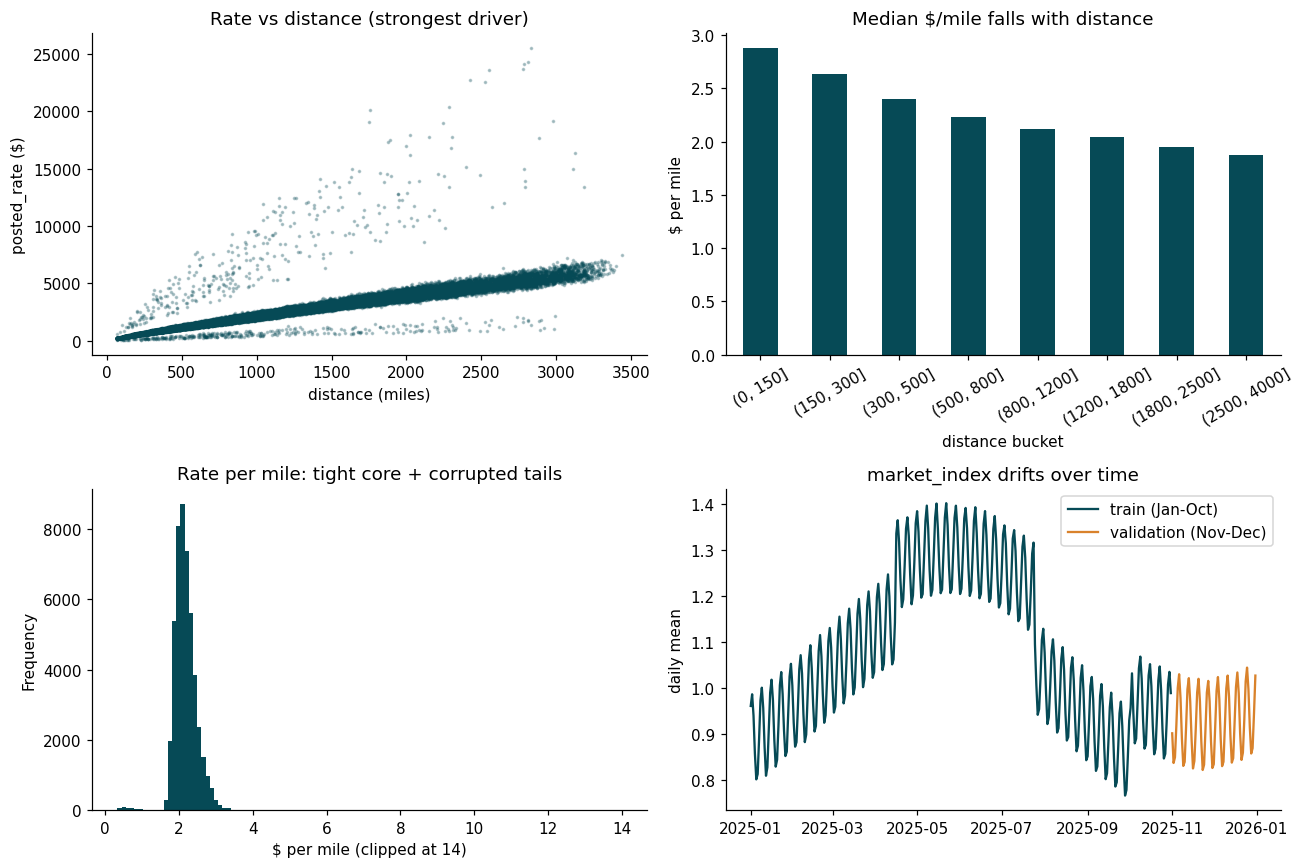

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))

ax[0, 0].scatter(train.distance, train.posted_rate, s=2, alpha=.25, color="#064A56")
ax[0, 0].set(title="Rate vs distance (strongest driver)", xlabel="distance (miles)", ylabel="posted_rate ($)")

bins = pd.cut(train.distance, [0, 150, 300, 500, 800, 1200, 1800, 2500, 4000])
train.groupby(bins, observed=True).rpm.median().plot.bar(ax=ax[0, 1], color="#064A56")
ax[0, 1].set(title="Median $/mile falls with distance", xlabel="distance bucket", ylabel="$ per mile")
ax[0, 1].tick_params(axis="x", rotation=30)

train.rpm.clip(0, 14).plot.hist(bins=120, ax=ax[1, 0], color="#064A56")
ax[1, 0].set(title="Rate per mile: tight core + corrupted tails", xlabel="$ per mile (clipped at 14)")

tr_m = train.groupby("date").market_index.mean(); va_m = val.groupby("date").market_index.mean()
ax[1, 1].plot(tr_m.index, tr_m.values, label="train (Jan-Oct)", color="#064A56")
ax[1, 1].plot(va_m.index, va_m.values, label="validation (Nov-Dec)", color="#D9822B")
ax[1, 1].set(title="market_index drifts over time", ylabel="daily mean"); ax[1, 1].legend()
plt.tight_layout(); plt.show()

In [ ]:
ok = train[(train.rpm > .9) & (train.rpm < 4)]
print("Median $/mile by equipment:"); print(ok.groupby("equipment").rpm.median().round(3).to_string())

qb = pd.cut(ok.quote_signal, [0, 1.5, 1.8, 2.0, 2.2, 2.5, 4])
print("\nMedian $/mile by quote_signal (U-shaped, non-linear):"); print(ok.groupby(qb, observed=True).rpm.median().round(3).to_string())

print("\nSpearman correlation with posted_rate:")
print(train[["distance", "weight", "market_index", "quote_signal"]].corrwith(train.posted_rate, method="spearman").round(3).to_string())

Median $/mile by equipment:
equipment
Dry Van    2.046
Flatbed    2.219
Reefer     2.312

Median $/mile by quote_signal (U-shaped, non-linear):
quote_signal
(0.0, 1.5]    2.783
(1.5, 1.8]    2.398
(1.8, 2.0]    2.023
(2.0, 2.2]    2.079
(2.2, 2.5]    2.253
(2.5, 4.0]    2.650

Spearman correlation with posted_rate:
distance        0.976
weight          0.042
market_index    0.032
quote_signal   -0.040


### Key findings
* **Distance explains almost everything** (Spearman 0.98 with rate). Rate per mile falls from about \$2.9 on short hauls to about \$1.9 above 2,500 miles, so the relationship is non-linear.
* **Reefer > Flatbed > Dry Van** in rate per mile.
* **`quote_signal` has a U-shaped effect** and **weight** a mild positive effect, so tree models fit better than a linear model.
* **`market_index` is a market-wide daily level** that drifts over time (about 1.08 in train vs 0.93 in validation), so time must be handled carefully.
* **Rate per mile has a tight core plus two small tails** (about 3.6x too high and about 0.3x too low): corrupted labels.

## 3. Data-quality audit

In [ ]:
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 3958.8 * 2 * np.arcsin(np.sqrt(a))

audit = pd.DataFrame({
    "train": {
        "rows": len(train),
        "duplicate load_id": train.load_id.duplicated().sum(),
        "negative weight": (train.weight < 0).sum(),
        "weight at 47,500 cap (abs)": (train.weight.abs() >= 47500).sum(),
        "missing weight": train.weight.isna().sum(),
        "missing market_index": train.market_index.isna().sum(),
        "rate/mile > 4 (corrupt high)": (train.rpm > 4).sum(),
        "rate/mile < 0.9 (corrupt low)": (train.rpm < 0.9).sum(),
    },
    "validation": {
        "rows": len(val),
        "duplicate load_id": val.load_id.duplicated().sum(),
        "negative weight": (val.weight < 0).sum(),
        "weight at 47,500 cap (abs)": (val.weight.abs() >= 47500).sum(),
        "missing weight": val.weight.isna().sum(),
        "missing market_index": val.market_index.isna().sum(),
        "rate/mile > 4 (corrupt high)": np.nan,
        "rate/mile < 0.9 (corrupt low)": np.nan,
    },
})
display(audit)

cities_tr = set(train.pickup) | set(train.delivery)
cities_va = set(val.pickup) | set(val.delivery)
new_cities = sorted(cities_va - cities_tr)
n_new = (val.pickup.isin(new_cities) | val.delivery.isin(new_cities)).sum()
print(f"\nCities only in validation ({len(new_cities)}): {new_cities}  -> {n_new:,} loads ({n_new/len(val):.1%})")

dm = train.groupby("date").market_index
print(f"market_index within-day std {dm.std().mean():.3f} vs between-day std {dm.mean().std():.3f}  -> a daily market level")
print(f"market_index mean: train {train.market_index.mean():.3f} vs validation {val.market_index.mean():.3f}")

g = train.groupby(["pickup", "delivery"]).distance
print(f"same-route distance noise (avg CV): {(g.std() / g.mean()).mean():.2%}")

,train,validation
rows,48000,12000.0
duplicate load_id,0,0.0
negative weight,292,145.0
"weight at 47,500 cap (abs)",1204,301.0
missing weight,300,165.0
missing market_index,374,249.0
rate/mile > 4 (corrupt high),340,NaN
rate/mile < 0.9 (corrupt low),307,NaN



Cities only in validation (8): ['Allentown', 'Charlotte', 'Chicago', 'Jackson', 'Knoxville', 'Laredo', 'Norfolk', 'San Diego']  -> 1,447 loads (12.1%)
market_index within-day std 0.025 vs between-day std 0.167  -> a daily market level
market_index mean: train 1.083 vs validation 0.927
same-route distance noise (avg CV): 1.98%


### How each issue is handled
| Issue | Handling |
|---|---|
| Negative weights (292 train / 145 val) | Sign errors: use `abs(weight)` |
| Weight capped at 47,500 | `weight_capped` flag |
| Missing weight | Keep as NaN (LightGBM routes missing values natively) + `weight_missing` flag |
| Missing market_index | Fill with the **same-day median** (it is a market-wide daily level) + flag |
| Corrupted target labels (~1.35%) | **Robust L1 loss** (predicts the conditional median); cannot be removed at test time |
| Unseen cities in validation | Use lat/lon, distance and bearing, **not** city IDs; add an unseen-city validation fold |
| Market drift | No raw month/trend feature; `market_index` carries the time signal |
| Noisy per-load distance | Add route-mean distance (features only, no labels), haversine and road factor |

## 4. Cleaning and feature engineering

In [ ]:
WEIGHT_CAP = 47_500.0
EQUIPMENT = ["Dry Van", "Flatbed", "Reefer"]
FEATURES = [
    "distance", "log_distance", "haversine", "road_factor", "route_distance",
    "equipment", "weight", "weight_missing", "weight_capped",
    "market_index", "market_index_missing", "quote_signal",
    "dow", "is_weekend", "day_of_month",
    "pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon",
    "d_lat", "d_lon", "bearing_sin", "bearing_cos",
]

def daily_market_index(*frames):
    """Median market_index per date pooled over all files (features only, no labels)."""
    allrows = pd.concat([f[["date", "market_index"]] for f in frames])
    return allrows.groupby("date")["market_index"].median()

def route_distance_table(*frames):
    """Mean recorded distance per directed (pickup, delivery) pair (features only, no labels)."""
    allrows = pd.concat([f[["pickup", "delivery", "distance"]] for f in frames])
    return allrows.groupby(["pickup", "delivery"])["distance"].mean()

def build_features(df, daily_mi, route_dist):
    out = pd.DataFrame(index=df.index)
    date = pd.to_datetime(df["date"])

    w = df["weight"].abs()                                   # negative weights are sign errors
    out["weight_missing"] = w.isna().astype(int)
    out["weight_capped"] = (w >= WEIGHT_CAP).astype(int)
    out["weight"] = w

    mi = df["market_index"]
    out["market_index_missing"] = mi.isna().astype(int)
    out["market_index"] = mi.fillna(date.map(daily_mi))      # same-day median

    out["distance"] = df["distance"]
    out["log_distance"] = np.log(df["distance"])
    out["haversine"] = haversine(df.pickup_lat, df.pickup_lon, df.delivery_lat, df.delivery_lon)
    out["road_factor"] = df["distance"] / out["haversine"]
    idx = pd.MultiIndex.from_arrays([df["pickup"], df["delivery"]])
    out["route_distance"] = route_dist.reindex(idx).to_numpy()
    for c in ["pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon"]:
        out[c] = df[c]
    out["d_lat"] = df.delivery_lat - df.pickup_lat
    out["d_lon"] = df.delivery_lon - df.pickup_lon
    ang = np.arctan2(out["d_lat"], out["d_lon"])
    out["bearing_sin"], out["bearing_cos"] = np.sin(ang), np.cos(ang)

    out["equipment"] = pd.Categorical(df["equipment"], categories=EQUIPMENT)
    out["quote_signal"] = df["quote_signal"]

    out["dow"] = date.dt.dayofweek
    out["is_weekend"] = (out["dow"] >= 5).astype(int)
    out["day_of_month"] = date.dt.day
    return out[FEATURES]

daily_mi = daily_market_index(train, val)
route_dist = route_distance_table(train, val)

X = build_features(train, daily_mi, route_dist).reset_index(drop=True)
y = train["posted_rate"].to_numpy()
y_log = np.log(y)
month = train["date"].dt.month.to_numpy()
print("feature matrix:", X.shape, "| remaining NaN:", X.isna().sum()[X.isna().sum() > 0].to_dict())
X.head(3)

feature matrix: (48000, 23) | remaining NaN: {'weight': 300}


,distance,log_distance,haversine,road_factor,route_distance,equipment,weight,weight_missing,weight_capped,market_index,market_index_missing,quote_signal,dow,is_weekend,day_of_month,pickup_lat,pickup_lon,delivery_lat,delivery_lon,d_lat,d_lon,bearing_sin,bearing_cos
0,274.3,5.614222,219.808768,1.247903,273.494444,Dry Van,30658.0,0,0,0.95684,0,2.39595,2,0,1,38.09122,-76.78906,38.16908,-72.74564,0.07786,4.04342,0.019252,0.999815
1,280.5,5.636574,220.525617,1.271961,274.852778,Reefer,17555.0,0,0,0.97623,0,2.43355,2,0,1,38.09122,-76.78906,39.22317,-72.96710,1.13195,3.82196,0.283977,0.958831
2,967.8,6.875025,826.919847,1.170367,970.737500,Dry Van,31721.0,0,0,1.00971,0,1.84491,2,0,1,39.22317,-72.96710,44.30296,-87.52871,5.07979,-14.56161,0.329381,-0.944197


## 5. Train/test split and validation strategy

The final validation file is **the future** (Nov-Dec) relative to the labelled data (Jan-Oct) and contains **unseen cities**. A random K-fold would let the model see same-day market conditions during training and overstate accuracy, so validation mimics the real task:

| Fold | Train | Test | Purpose |
|---|---|---|---|
| **A** | Jan-Jun | Jul-Aug | Forward chaining |
| **B** | Jan-Aug | Sep-Oct | Closest analogue of Nov-Dec |
| **C** | Jan-Aug, minus loads touching 6 held-out cities | Sep-Oct, loads touching those cities | Unseen-city generalisation |

Metrics are reported on **raw** test rows (labels as given) and on **clean** rows (rate per mile within $0.9-$4.0), which separates model error from label corruption.
No labels are used by any feature, so there is no target leakage.

In [ ]:
LGB_BASE = dict(
    n_estimators=1500, learning_rate=0.03, num_leaves=31, min_child_samples=40,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
    random_state=SEED, n_jobs=-1, verbose=-1,
)

def metrics(y_true, p):
    err = p - y_true
    return {"MAE": np.mean(np.abs(err)), "RMSE": np.sqrt(np.mean(err ** 2)),
            "MAPE_%": np.mean(np.abs(err) / y_true) * 100,
            "MedAPE_%": np.median(np.abs(err) / y_true) * 100,
            "R2": 1 - np.sum(err ** 2) / np.sum((y_true - y_true.mean()) ** 2)}

def flag_label_outliers(X, y_log, mask_train, threshold=0.4):
    """Out-of-fold log-residual from a Huber LightGBM; drop labels with |resid| > threshold."""
    idx = np.where(mask_train)[0]
    resid = np.zeros(len(idx))
    params = {**LGB_BASE, "n_estimators": 400, "learning_rate": 0.08, "objective": "huber", "alpha": 0.3}
    for a, b in KFold(5, shuffle=True, random_state=SEED).split(idx):
        m = lgb.LGBMRegressor(**params).fit(X.iloc[idx[a]], y_log[idx[a]])
        resid[b] = y_log[idx[b]] - m.predict(X.iloc[idx[b]])
    keep = np.abs(resid) <= threshold
    return idx[keep], int((~keep).sum())

def ridge_matrix(d):
    M = d[["log_distance", "market_index", "quote_signal"]].copy()
    M["w"] = d["weight"].fillna(d["weight"].median()) / 1e4
    M["q_sq"] = (d["quote_signal"] - 2.05) ** 2
    return pd.concat([M, pd.get_dummies(d["equipment"], dtype=float)], axis=1)

def fit_predict(name, tr_idx, te_idx):
    Xtr, Xte, ytr = X.iloc[tr_idx], X.iloc[te_idx], y_log[tr_idx]
    if name == "baseline_median_rate_per_mile":
        return np.median(np.exp(ytr) / Xtr["distance"].to_numpy()) * Xte["distance"].to_numpy()
    if name == "ridge_log_linear":
        return np.exp(Ridge(alpha=1.0).fit(ridge_matrix(Xtr), ytr).predict(ridge_matrix(Xte)))
    kind = {"lgbm_l2": dict(objective="regression"),
            "lgbm_huber": dict(objective="huber", alpha=0.3),
            "lgbm_l1": dict(objective="regression_l1")}[name]
    return np.exp(lgb.LGBMRegressor(**{**LGB_BASE, **kind}).fit(Xtr, ytr).predict(Xte))

MODELS = ["baseline_median_rate_per_mile", "ridge_log_linear", "lgbm_l2", "lgbm_huber", "lgbm_l1", "lgbm_l2_cleaned_labels"]
rpm_all = y / X["distance"].to_numpy()
clean_all = (rpm_all > 0.9) & (rpm_all < 4.0)

def run_fold(label, train_mask, test_mask):
    rows = []
    te = np.where(test_mask)[0]
    for name in MODELS:
        if name == "lgbm_l2_cleaned_labels":
            tr_idx, dropped = flag_label_outliers(X, y_log, train_mask)
            pred = fit_predict("lgbm_l2", tr_idx, te)
        else:
            pred = fit_predict(name, np.where(train_mask)[0], te); dropped = 0
        raw = metrics(y[te], pred)
        cl = metrics(y[te][clean_all[te]], pred[clean_all[te]])
        rows.append({"fold": label, "model": name, "dropped_labels": dropped,
                     **{f"raw_{k}": v for k, v in raw.items()}, **{f"clean_{k}": v for k, v in cl.items()}})
    return rows

rng = np.random.default_rng(SEED)
all_cities = np.array(sorted(cities_tr))
held = sorted(str(c) for c in rng.choice(all_cities, 6, replace=False))
touches = (train.pickup.isin(held) | train.delivery.isin(held)).to_numpy()
print("Fold C held-out cities:", held)

results = []
results += run_fold("A: Jan-Jun -> Jul-Aug", month <= 6, (month >= 7) & (month <= 8))
results += run_fold("B: Jan-Aug -> Sep-Oct", month <= 8, month >= 9)
results += run_fold("C: unseen cities", (month <= 8) & ~touches, (month >= 9) & touches)
res = pd.DataFrame(results)
res.to_csv("outputs/validation_metrics.csv", index=False)
print("done")

Fold C held-out cities: ['Bakersfield', 'Houston', 'Milwaukee', 'Philadelphia', 'San Francisco', 'Tulsa']


done


## 6. Model comparison

In [ ]:
cols = ["fold", "model", "dropped_labels", "raw_MAE", "raw_MAPE_%", "clean_MAE", "clean_MAPE_%", "clean_R2"]
display(res[cols].round(3).style.format({c: "{:.2f}" for c in cols[3:]}).background_gradient(subset=["clean_MAPE_%"], cmap="Greens_r"))

,fold,model,dropped_labels,raw_MAE,raw_MAPE_%,clean_MAE,clean_MAPE_%,clean_R2
0,A: Jan-Jun -> Jul-Aug,baseline_median_rate_per_mile,0,249.01,11.16,199.52,9.13,0.95
1,A: Jan-Jun -> Jul-Aug,ridge_log_linear,0,118.75,5.39,67.46,3.32,0.99
2,A: Jan-Jun -> Jul-Aug,lgbm_l2,0,132.34,5.95,81.24,3.89,0.99
3,A: Jan-Jun -> Jul-Aug,lgbm_huber,0,113.91,5.14,62.68,3.08,0.99
4,A: Jan-Jun -> Jul-Aug,lgbm_l1,0,115.95,5.19,64.75,3.12,0.99
5,A: Jan-Jun -> Jul-Aug,lgbm_l2_cleaned_labels,400,111.78,5.04,60.57,2.98,1.00
6,B: Jan-Aug -> Sep-Oct,baseline_median_rate_per_mile,0,256.95,11.63,204.04,9.37,0.95
7,B: Jan-Aug -> Sep-Oct,ridge_log_linear,0,159.38,6.77,104.67,4.50,0.99
8,B: Jan-Aug -> Sep-Oct,lgbm_l2,0,156.46,6.75,101.85,4.46,0.99
9,B: Jan-Aug -> Sep-Oct,lgbm_huber,0,148.13,6.32,93.37,4.03,0.99


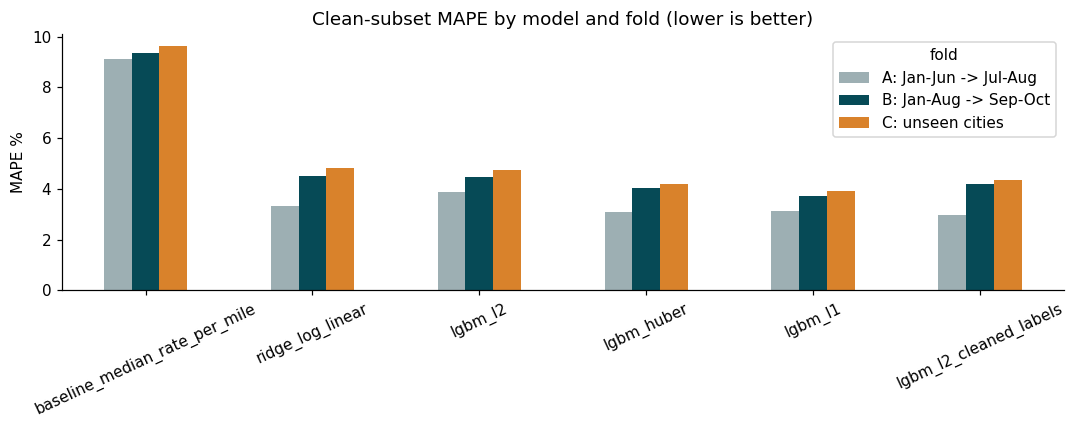

In [ ]:
piv = res.pivot(index="model", columns="fold", values="clean_MAPE_%").loc[MODELS]
ax = piv.plot.bar(figsize=(10, 4), rot=25, color=["#9DAFB3", "#064A56", "#D9822B"])
ax.set(title="Clean-subset MAPE by model and fold (lower is better)", ylabel="MAPE %", xlabel="")
plt.tight_layout(); plt.show()

**Conclusions**
* A distance-only baseline is far behind (about 9% clean MAPE), so features and non-linearity matter.
* Tree models with a **robust loss (L1 / Huber)** beat L2 on the raw test set, since about 1.35% of labels are corrupted and L2 chases them.
* **L1 on log(rate)** is the best single model on fold B (the closest analogue of the real task) and on the unseen-city fold C, so it generalises to new cities.
* Dropping suspected bad labels from training (`lgbm_l2_cleaned_labels`) helps L2 but is not better than L1, and it needs a hand-tuned threshold; L1 is simpler and more robust.

**Final model:** a bag of 6 LightGBM models (2 tree sizes x 3 seeds), L1 loss on `log(posted_rate)`, averaged in log space.

In [ ]:
# Evaluate the final bagged ensemble on folds A and B
CONFIGS = [dict(), dict(num_leaves=63, min_child_samples=20)]
SEEDS = [0, 1, 2]
BASE = {**LGB_BASE, "objective": "regression_l1"}

def fit_ensemble(Xd, yl):
    return [lgb.LGBMRegressor(**{**BASE, **cfg, "random_state": s}).fit(Xd, yl) for cfg in CONFIGS for s in SEEDS]

def predict_ensemble(models, Xd):
    return np.exp(np.mean([m.predict(Xd) for m in models], axis=0))   # average in log space

rows = []
for label, trm, tem in [("A: Jan-Jun -> Jul-Aug", month <= 6, (month >= 7) & (month <= 8)),
                        ("B: Jan-Aug -> Sep-Oct", month <= 8, month >= 9)]:
    ti, te = np.where(trm)[0], np.where(tem)[0]
    p = predict_ensemble(fit_ensemble(X.iloc[ti], y_log[ti]), X.iloc[te])
    r, c = metrics(y[te], p), metrics(y[te][clean_all[te]], p[clean_all[te]])
    rows.append({"fold": label, **{f"raw_{k}": v for k, v in r.items()}, **{f"clean_{k}": v for k, v in c.items()}})
final_cv = pd.DataFrame(rows).set_index("fold")
final_cv.to_csv("outputs/final_model_cv.csv")
final_cv.round(3)

,raw_MAE,raw_RMSE,raw_MAPE_%,raw_MedAPE_%,raw_R2,clean_MAE,clean_RMSE,clean_MAPE_%,clean_MedAPE_%,clean_R2
fold,,,,,,,,,,
A: Jan-Jun -> Jul-Aug,116.268,626.612,5.180,2.111,0.823,65.057,99.688,3.113,2.073,0.995
B: Jan-Aug -> Sep-Oct,138.534,641.965,5.924,3.412,0.823,83.612,111.846,3.629,3.380,0.993


## 7. Final model and feature importance
Refit the ensemble on **all 48,000 labelled rows**.

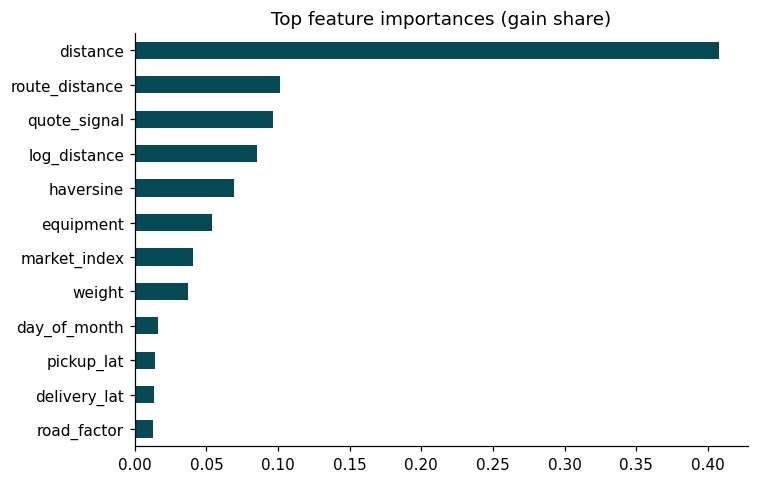

distance          0.408
route_distance    0.102
quote_signal      0.096
log_distance      0.085
haversine         0.069
equipment         0.054
market_index      0.041
weight            0.037


In [ ]:
final_models = fit_ensemble(X, y_log)

imp = pd.DataFrame({f"m{i}": m.booster_.feature_importance("gain") for i, m in enumerate(final_models)}, index=X.columns).mean(axis=1)
imp = (imp / imp.sum()).sort_values()
imp.tail(12).plot.barh(figsize=(7, 4.5), color="#064A56", title="Top feature importances (gain share)")
plt.tight_layout(); plt.show()
print(imp.sort_values(ascending=False).head(8).round(3).to_string())

## 8. Final predictions on `validation.csv`

In [ ]:
X_val = build_features(val, daily_mi, route_dist)
pred_val = predict_ensemble(final_models, X_val)

template = pd.read_csv(ROOT / "data/validation_predictions_template.csv")
sub = template[["load_id"]].merge(
    pd.DataFrame({"load_id": val["load_id"], "predicted_rate": pred_val.round(2)}), on="load_id", how="left")

assert len(sub) == 12_000 and sub.predicted_rate.notna().all() and (sub.predicted_rate > 0).all()
assert sub.load_id.is_unique and set(sub.load_id) == set(template.load_id)
sub.to_csv(ROOT / "validation_predictions.csv", index=False)

print(sub.shape, "->", "validation_predictions.csv")
print(sub.predicted_rate.describe().round(1).to_string())
sub.head()

(12000, 2) -> validation_predictions.csv
count    12000.0
mean      2323.6
std       1345.3
min        202.9
25%       1250.0
50%       1996.0
75%       3317.6
max       6685.2


,load_id,predicted_rate
0,TE-000001,817.02
1,TE-000002,4781.87
2,TE-000003,5260.45
3,TE-000004,4140.54
4,TE-000005,1772.74


In [ ]:
# Sanity check: predicted $/mile in validation should look like training's core band
chk = val.merge(sub, on="load_id")
rpm_pred = chk.predicted_rate / chk.distance
print("train median $/mile:", round(train.rpm.median(), 3), "| predicted validation median $/mile:", round(rpm_pred.median(), 3))

train median $/mile: 2.145 | predicted validation median $/mile: 2.118


## 9. Fixed December prediction chart

`data/december_chart_inputs.csv` only has pickup, delivery, distance, equipment, weight and date. The model also needs city coordinates (looked up from the data) and the two market features. For each December day we use the **observed daily median `market_index` and `quote_signal` from `validation.csv`** (feature columns only, no labels).

In [ ]:
dec = pd.read_csv(ROOT / "data/december_chart_inputs.csv")
d = dec.drop(columns="predicted_rate").copy()
d["date"] = pd.to_datetime(d["date"])

ref = pd.concat([train, val])
d = (d.join(ref.groupby("pickup")[["pickup_lat", "pickup_lon"]].first(), on="pickup")
      .join(ref.groupby("delivery")[["delivery_lat", "delivery_lon"]].first(), on="delivery"))
day = val.groupby("date")[["market_index", "quote_signal"]].median()
d["market_index"] = d["date"].map(day["market_index"])
d["quote_signal"] = d["date"].map(day["quote_signal"])

dec_out = dec.copy()
dec_out["predicted_rate"] = predict_ensemble(final_models, build_features(d, daily_mi, route_dist)).round(2)
dec_out.to_csv(ROOT / "data/december_chart_inputs.csv", index=False)
print(dec_out.predicted_rate.describe().round(2).to_string())
dec_out.head()

count     31.00
mean     803.57
std        4.92
min      795.77
25%      799.33
50%      803.57
75%      807.29
max      815.10


,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,797.71
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,803.57
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,807.57
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,808.34
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,802.56


Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: outputs/scorer_results/candidate_december.png
Final validation metrics are calculated by Spotter after submission.



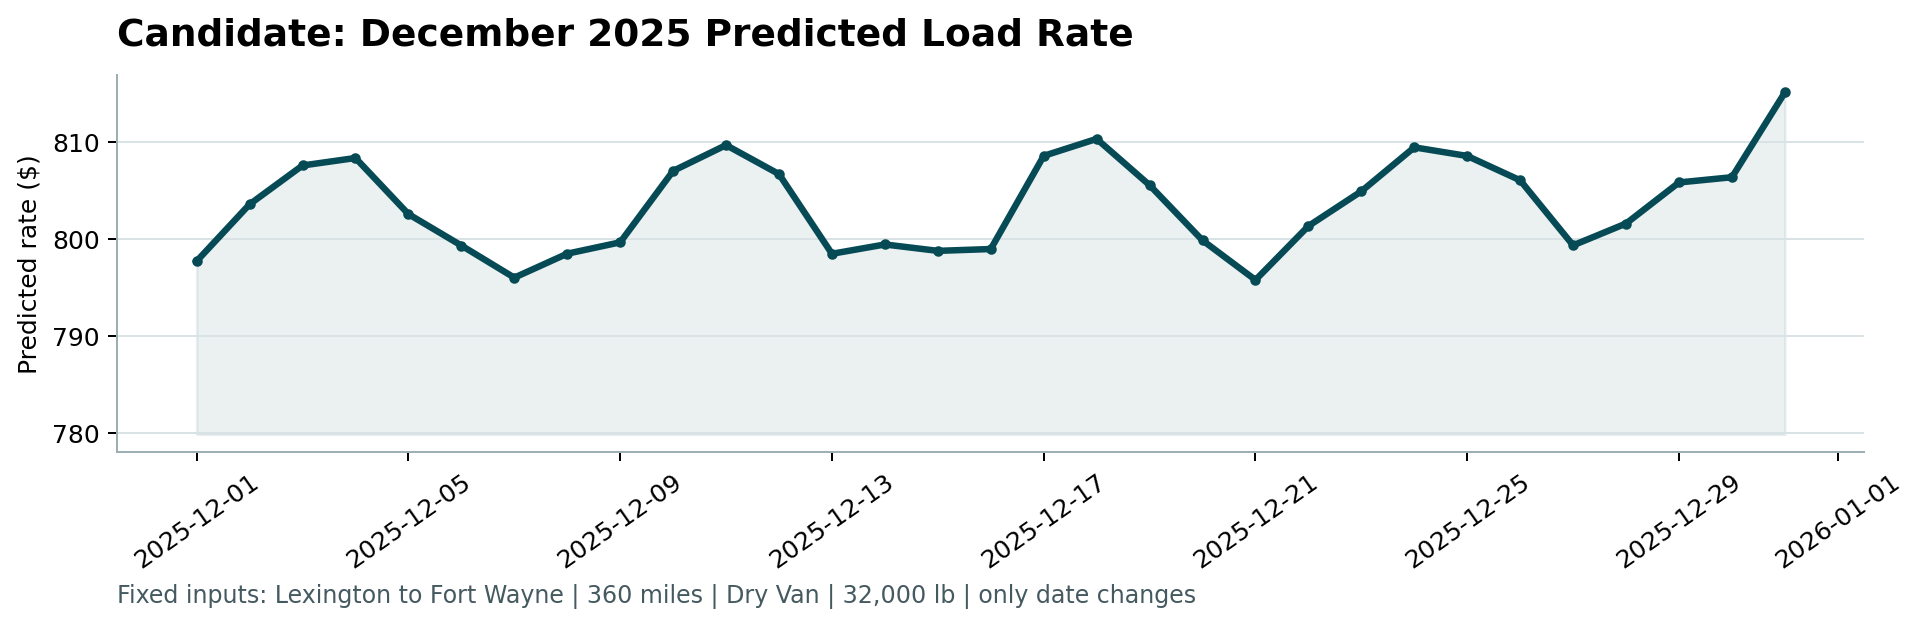

In [ ]:
out = subprocess.run([sys.executable, "score.py", "--predictions", "validation_predictions.csv",
                      "--december-predictions", "data/december_chart_inputs.csv",
                      "--output-dir", "outputs/scorer_results"], capture_output=True, text=True)
print(out.stdout or out.stderr)
display(Image("outputs/scorer_results/candidate_december.png"))

## Summary
* **Split:** time-based forward chaining (A, B) plus an unseen-city fold (C); never a random split.
* **Data quality:** sign-flipped and capped weights, missing weight / market_index, about 1.35% corrupted labels, market drift, 8 unseen cities, noisy distance.
* **Model:** bag of 6 LightGBM models, L1 loss on log(rate), refit on all 48,000 labelled rows.
* **Outputs:** `validation_predictions.csv` (12,000 rows), `data/december_chart_inputs.csv` (31 rows), `outputs/scorer_results/candidate_december.png`.